In [ ]:
import pandas as pd
df = pd.read_csv("/content/money_laundring_cleaned_and_feature_engineered.csv")
print(df.head(3))

        Day  hour  Sender_frequancy  Reciever_frequancy   Amount  \
0    Friday    10                 5                   1    92.61   
1   Tuesday    19               110                  25  5157.16   
2  Saturday     8                14                   3  7426.99   

  Payment_currency Received_currency  is_payment_same Sender_bank_location  \
0            Euros         UK pounds            False                   UK   
1        UK pounds         UK pounds             True                   UK   
2        UK pounds         UK pounds             True                  UAE   

  Receiver_bank_location  is_bank_same_location  Payment_type  Is_laundering  \
0                     UK                   True   Credit card              0   
1                  Japan                  False  Cross-border              1   
2                     UK                  False        Cheque              0   

        Laundering_type  
0  Normal_Small_Fan_Out  
1  Behavioural_Change_2  
2        Normal

       Day  hour  Sender_frequancy  Reciever_frequancy   Amount  \
1  Tuesday    19               110                  25  5157.16   
6  Tuesday     8                45                  23  5504.80   
9   Sunday    13                70                 132  7020.58   

  Payment_currency Received_currency  is_payment_same Sender_bank_location  \
1        UK pounds         UK pounds             True                   UK   
6        UK pounds         UK pounds             True                   UK   
9              Yen        US dollars            False                  UAE   

  Receiver_bank_location  is_bank_same_location  Payment_type  Is_laundering  \
1                  Japan                  False  Cross-border              1   
6                     US                  False  Cross-border              1   
9                     UK                  False        Cheque              1   

        Laundering_type  
1  Behavioural_Change_2  
6     Stacked Bipartite  
9        Layered_Fa

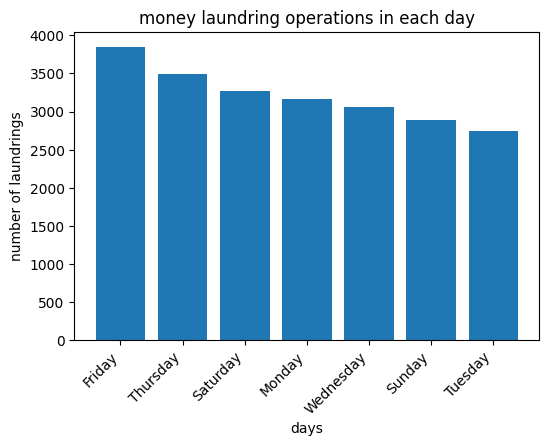

<Figure size 640x480 with 0 Axes>

In [3]:
import matplotlib.pyplot as plt
money_laundring = df[df['Is_laundering'] == 1]
day_counts = money_laundring['Day'].value_counts()
print(money_laundring.head(3))
fig,ax = plt.subplots(figsize = (6,4))

plt.bar(day_counts.index,day_counts)
plt.xlabel('days')
plt.ylabel('number of laundrings')
plt.title('money laundring operations in each day')
plt.xticks(rotation = 45,ha = 'right')
plt.show()
plt.savefig('money_laundring_days.png')

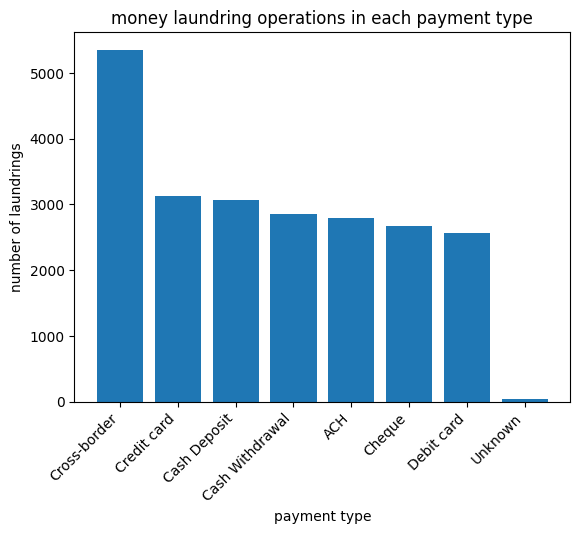

<Figure size 640x480 with 0 Axes>

In [4]:
payment_type_counts = money_laundring['Payment_type'].value_counts()
plt.bar(payment_type_counts.index,payment_type_counts)
plt.xlabel('payment type')
plt.ylabel('number of laundrings')
plt.title('money laundring operations in each payment type')
plt.xticks(rotation = 45,ha = 'right')
plt.show()
plt.savefig('money_laundring_payment_type.png')

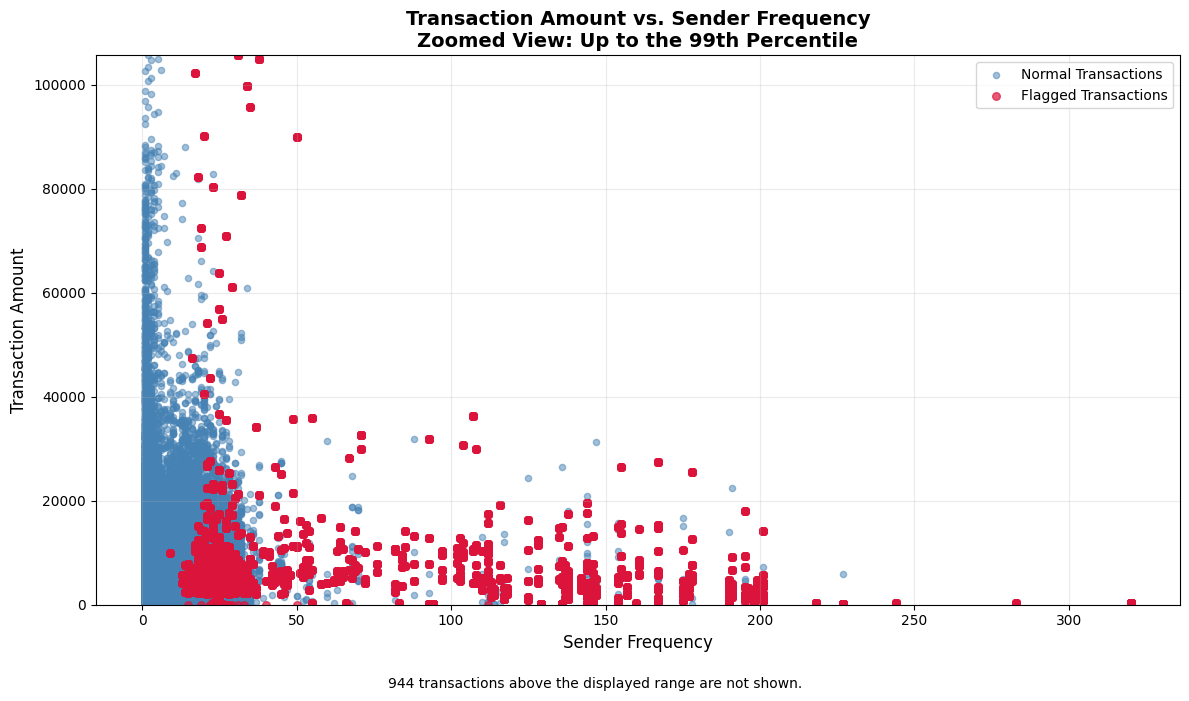

In [9]:


import matplotlib.pyplot as plt
import numpy as np

# Remove missing values from the required columns
plot_df = df[['Sender_frequancy', 'Amount', 'Is_laundering']].dropna()

# Focus on the range containing 99% of transaction amounts
upper_limit = plot_df['Amount'].quantile(0.99)

# Count transactions above the displayed range
hidden_count = (plot_df['Amount'] > upper_limit).sum()

normal = plot_df[plot_df['Is_laundering'] == 0]
flagged = plot_df[plot_df['Is_laundering'] == 1]

plt.figure(figsize=(12, 7))

plt.scatter(
    normal['Sender_frequancy'],
    normal['Amount'],
    color='steelblue',
    alpha=0.5,
    s=20,
    label='Normal Transactions'
)

plt.scatter(
    flagged['Sender_frequancy'],
    flagged['Amount'],
    color='crimson',
    alpha=0.7,
    s=30,
    label='Flagged Transactions'
)

# Use the original transaction amount scale
plt.ylim(bottom=0, top=upper_limit)

plt.title(
    'Transaction Amount vs. Sender Frequency\n'
    'Zoomed View: Up to the 99th Percentile',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Sender Frequency', fontsize=12)
plt.ylabel('Transaction Amount', fontsize=12)

plt.legend()
plt.grid(True, alpha=0.25)

plt.figtext(
    0.5, 0.01,
    f'{hidden_count:,} transactions above the displayed range '
    f'are not shown.',
    ha='center',
    fontsize=10
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig('Amount_Scatterplot_Linear.png', dpi=300)
plt.show()


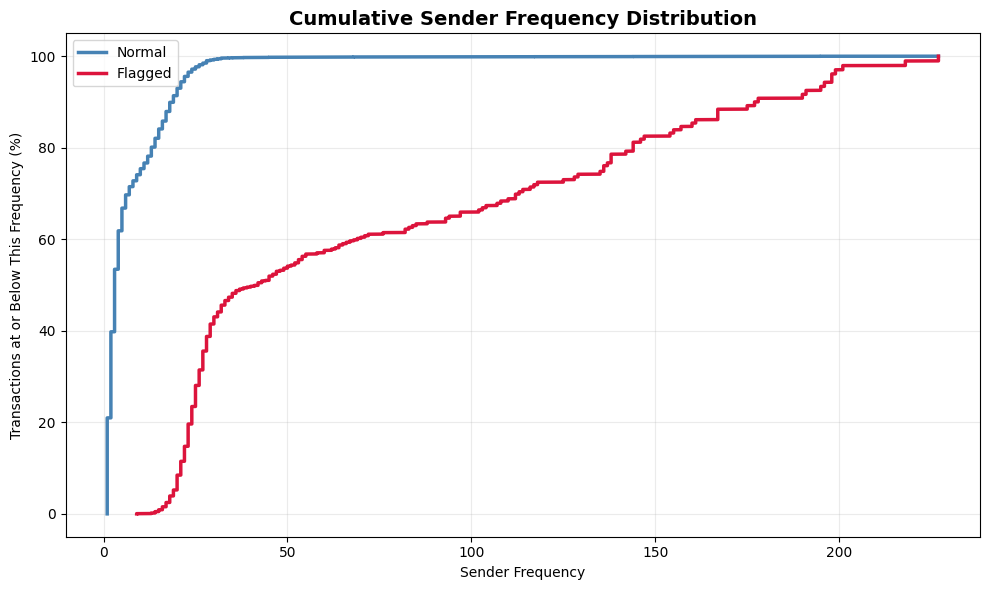

In [29]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for label, color, name in [
    (0, 'steelblue', 'Normal'),
    (1, 'crimson', 'Flagged')
]:
    values = df.loc[
        df['Is_laundering'] == label, 'Sender_frequancy'
    ].dropna().sort_values()

    # Focus the display on the 99th percentile
    limit = df['Sender_frequancy'].quantile(0.99)
    values = values[values <= limit].to_numpy()

    y = np.arange(1, len(values) + 1) / len(values) * 100

    plt.plot(values, y, color=color, linewidth=2.5, label=name)

plt.title('Cumulative Sender Frequency Distribution',
          fontsize=14, fontweight='bold')
plt.xlabel('Sender Frequency')
plt.ylabel('Transactions at or Below This Frequency (%)')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('sender_frequency_ecdf.png', dpi=300)
plt.show()



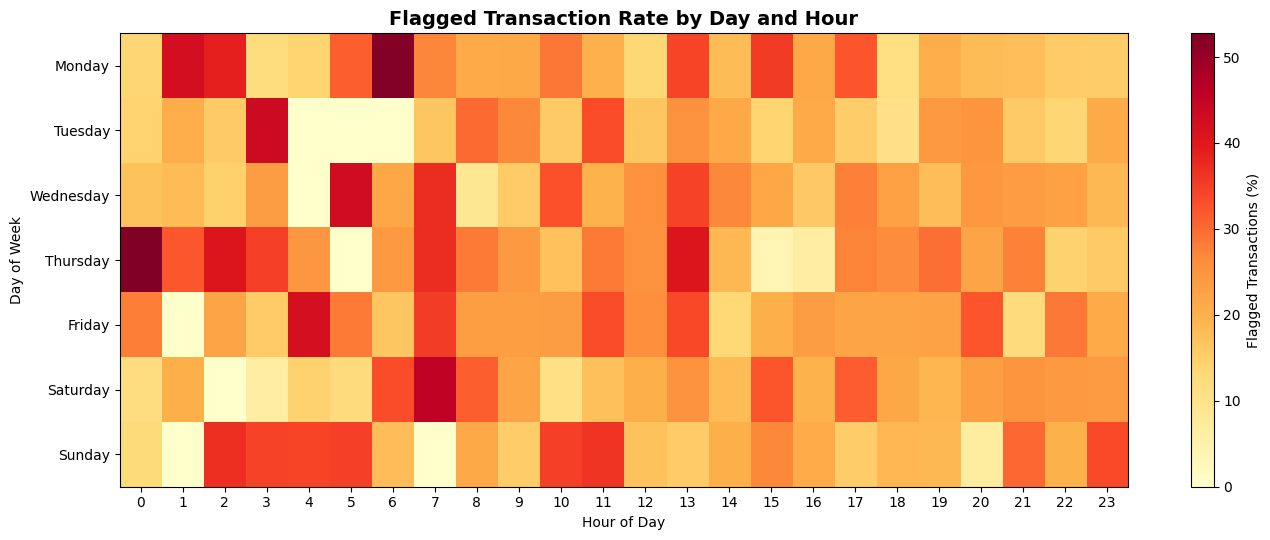

In [18]:


day_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

hourly = df.pivot_table(
    index='Day',
    columns='hour',
    values='Is_laundering',
    aggfunc='mean'
) * 100

hourly = hourly.reindex(index=day_order, columns=range(24))

fig, ax = plt.subplots(figsize=(14, 5.5))

im = ax.imshow(
    hourly.values,
    aspect='auto',
    cmap='YlOrRd',
    interpolation='nearest'
)

ax.set_xticks(range(24))
ax.set_xticklabels(range(24))
ax.set_yticks(range(len(day_order)))
ax.set_yticklabels(day_order)

ax.set_xlabel('Hour of Day')
ax.set_ylabel('Day of Week')
ax.set_title('Flagged Transaction Rate by Day and Hour',
             fontsize=14, fontweight='bold')

cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Flagged Transactions (%)')

plt.tight_layout()
plt.savefig('day_hour_heatmap.png', dpi=300)
plt.show()



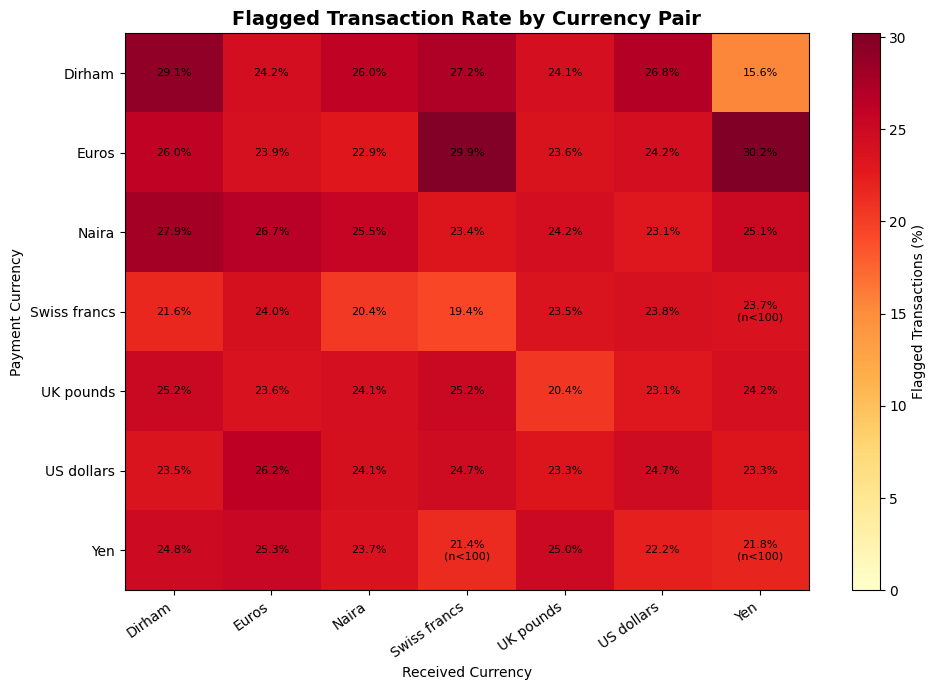

In [19]:


currency_rate = df.pivot_table(
    index='Payment_currency',
    columns='Received_currency',
    values='Is_laundering',
    aggfunc='mean'
) * 100

currency_counts = df.pivot_table(
    index='Payment_currency',
    columns='Received_currency',
    values='Is_laundering',
    aggfunc='count'
)

fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(
    currency_rate.values,
    cmap='YlOrRd',
    aspect='auto',
    vmin=0
)

for i in range(currency_rate.shape[0]):
    for j in range(currency_rate.shape[1]):
        rate = currency_rate.iloc[i, j]
        count = currency_counts.iloc[i, j]

        if pd.notna(rate):
            label = f'{rate:.1f}%'
            if pd.notna(count) and count < 100:
                label += '\n(n<100)'

            ax.text(
                j, i, label,
                ha='center', va='center',
                fontsize=8,
                color='black'
            )

ax.set_xticks(range(len(currency_rate.columns)))
ax.set_xticklabels(currency_rate.columns, rotation=35, ha='right')
ax.set_yticks(range(len(currency_rate.index)))
ax.set_yticklabels(currency_rate.index)

ax.set_xlabel('Received Currency')
ax.set_ylabel('Payment Currency')
ax.set_title('Flagged Transaction Rate by Currency Pair',
             fontsize=14, fontweight='bold')

cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Flagged Transactions (%)')

plt.tight_layout()
plt.savefig('currency_pair_heatmap.png', dpi=300)
plt.show()


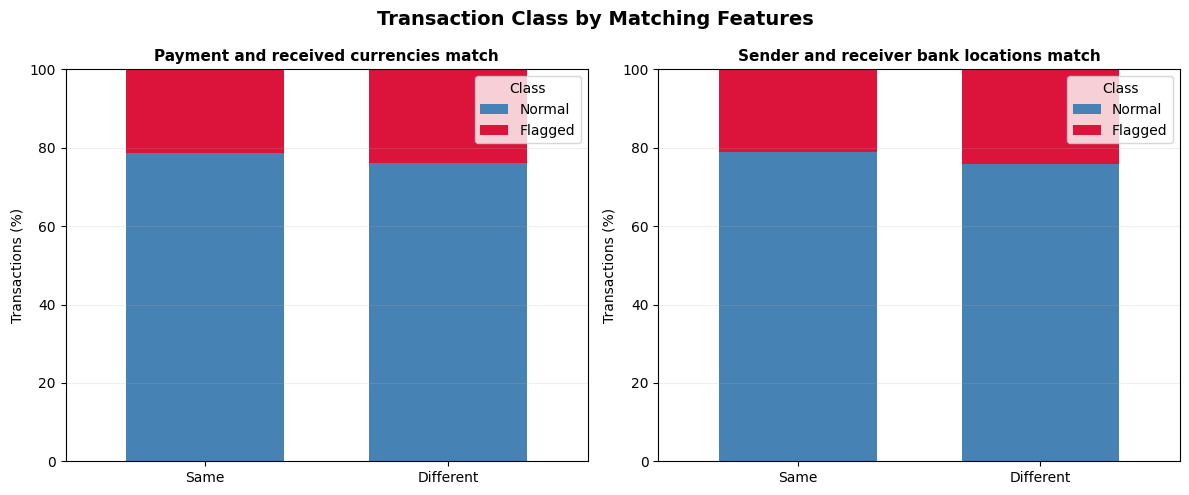

In [21]:


features = [
    ('is_payment_same', 'Payment and received currencies match'),
    ('is_bank_same_location', 'Sender and receiver bank locations match')
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (column, title) in zip(axes, features):
    proportions = pd.crosstab(
        df[column].map({True: 'Same', False: 'Different'}),
        df['Is_laundering'],
        normalize='index'
    ) * 100

    proportions = proportions.reindex(
        ['Same', 'Different']
    ).reindex(columns=[0, 1], fill_value=0)

    proportions = proportions.rename(
        columns={0: 'Normal', 1: 'Flagged'}
    )

    proportions.plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=['steelblue', 'crimson'],
        width=0.65
    )

    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Transactions (%)')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title='Class')
    ax.grid(axis='y', alpha=0.2)

plt.suptitle('Transaction Class by Matching Features',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('matching_features_stacked.png', dpi=300)
plt.show()




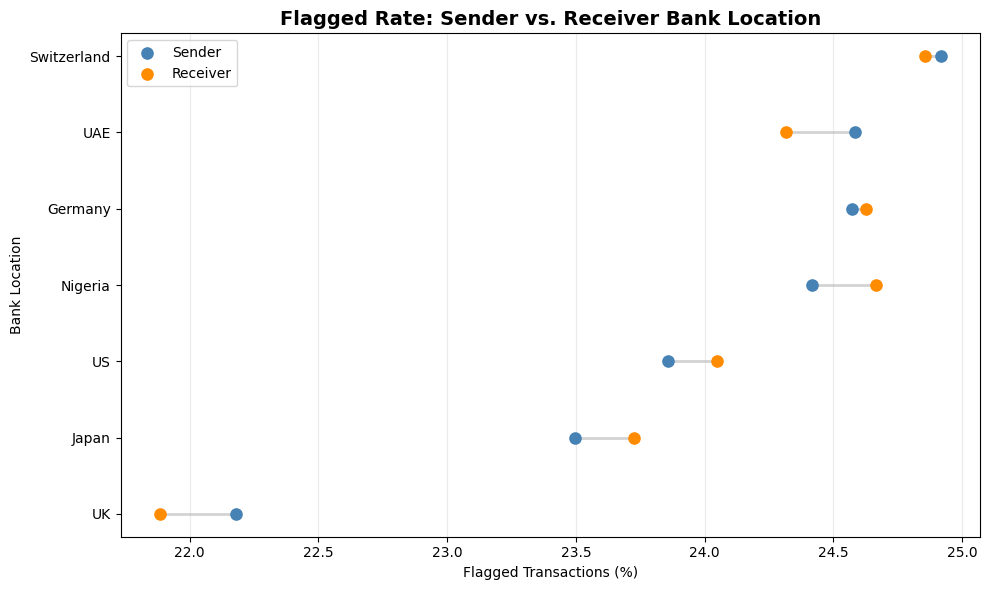

In [23]:


sender_rate = (
    df.groupby('Sender_bank_location')['Is_laundering'].mean() * 100
)

receiver_rate = (
    df.groupby('Receiver_bank_location')['Is_laundering'].mean() * 100
)

locations = sorted(
    set(sender_rate.index) | set(receiver_rate.index)
)

comparison = pd.DataFrame({
    'Sender': sender_rate.reindex(locations),
    'Receiver': receiver_rate.reindex(locations)
}).dropna()

comparison = comparison.sort_values('Sender')

fig, ax = plt.subplots(figsize=(10, 6))

for y, (location, row) in enumerate(comparison.iterrows()):
    ax.plot(
        [row['Sender'], row['Receiver']],
        [y, y],
        color='lightgray',
        linewidth=2,
        zorder=1
    )

    ax.scatter(row['Sender'], y, color='steelblue',
               s=65, label='Sender' if y == 0 else '', zorder=2)

    ax.scatter(row['Receiver'], y, color='darkorange',
               s=65, label='Receiver' if y == 0 else '', zorder=2)

ax.set_yticks(range(len(comparison)))
ax.set_yticklabels(comparison.index)
ax.set_xlabel('Flagged Transactions (%)')
ax.set_ylabel('Bank Location')
ax.set_title('Flagged Rate: Sender vs. Receiver Bank Location',
             fontsize=14, fontweight='bold')
ax.legend()
ax.grid(axis='x', alpha=0.25)

plt.tight_layout()
plt.savefig('bank_location_dumbbell.png', dpi=300)
plt.show()


